# 02 — Return distributions (`EXP-H01`)

## 1. Objective

Compare Gaussian and Student-t models of BTCUSDT log-return densities.

## 2. Hypothesis

A Student-t model is better calibrated than a Gaussian model at the 5-, 15-, and 60-minute horizons.

## 3. Null

The Student-t model adds no calibration value on that pre-registered family.

## 4. Information set

Each label uses only the close at the decision time and the close exactly one horizon later. No same-bar high or low, no future bar, and no local clock.

## 5. Dataset and version

`research/registry/datasets/btcusdt-1m.json`, loaded from `s3://trading-data-centheos` with AWS profile `trading`.

## 6. Data-quality checks

The dataset freeze counts duplicates, off-grid rows, bad prices, inconsistent OHLC, and missing minutes.

## 7. Label definition

`log(close[t + h]) - log(close[t])` only when both minute bars exist. A gap does not become a longer return.

## 8. Baseline

The nested baseline is the Gaussian model fit on the same training labels.

## 9. Model / method

Gaussian maximum likelihood. Student-t method of moments using mean, variance, and unbiased excess kurtosis. A non-positive excess kurtosis fails that window rather than silently reverting to a Gaussian.

## 10. Training / validation / test split

Rolling 24-month train and 6-month validation windows, stepped by 6 months. The final 12 calendar months are sealed. A label whose outcome falls beyond a block boundary leaves that block.

## 11. Experiment configuration

`research.protocol.H1_CONFIG`. Its digest is printed below.


In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
while root != root.parent and not (root / "research" / "__init__.py").exists():
    root = root.parent
if not (root / "research" / "__init__.py").exists():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("AWS_PROFILE", "trading")
os.environ.setdefault("AWS_DEFAULT_REGION", "ap-southeast-2")
os.environ.setdefault("DATA_STORE", "s3")
os.environ.setdefault("S3_BUCKET", "trading-data-centheos")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.6g}".format)

from research.registry import config_digest, load_record
from research.report import (
    calibration_summary,
    confirmation_blockers,
    model_colors,
    plain_english_result,
    plot_advantage_by_origin,
    plot_density_panels,
    plot_pit_qq,
    plot_score_levels,
    plot_shortfall,
    plot_var_hit_rates,
    quality_table,
    record_development_decision,
    score_reading,
)

## 5–6. Dataset and data quality

The frozen manifest is reloaded and verified. Every audit exclusion is counted in the table.

In [2]:
from research.evaluate import align_to_frozen_dataset
from research.load import load_research_bars
from research.manifest import load_manifest
from research.protocol import H1_CONFIG

frozen = load_manifest(root / "research" / "registry" / "datasets" / "btcusdt-1m.json")
bars, objects = load_research_bars(
    venue=H1_CONFIG["venue"],
    symbol=H1_CONFIG["symbol"],
    timeframe=H1_CONFIG["timeframe"],
    bucket=H1_CONFIG["bucket"],
    profile=H1_CONFIG["profile"],
    region=H1_CONFIG["region"],
)
kept, report, appended = align_to_frozen_dataset(bars, frozen, objects)
print(f"dataset {frozen.dataset_id} digest {frozen.digest}")
print(f"frozen window {frozen.start} to {frozen.end}; collector rows after the freeze excluded: {appended}")
display(quality_table({H1_CONFIG["symbol"]: report}))

Excluded 63 collector rows after frozen end 2026-10-26T06:22:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag b0d44f18eb613200b2a60b3c53423626 -> 9448670f00756206caaf822f402fe16e, size 5811263 -> 5813005


dataset btcusdt-1m digest d67871b2eebd796cb37c7cafa89677fbca4b31ad0bdae959a5f0e2efeecc6c88
frozen window 2020-01-01T00:00:00+00:00 to 2026-10-26T06:22:00+00:00; collector rows after the freeze excluded: 63


,rows_in,rows_kept,duplicate_timestamps,off_grid_timestamps,nonpositive_prices,inconsistent_ohlc,missing_minutes,largest_gap_minutes
series,,,,,,,,
BTCUSDT,3585983,3585983,0,0,0,0,0,1


## 12–17. Evaluation

The evaluation compares Student-t with the nested Gaussian at every rolling origin. The null is rejected only when Student-t has a positive mean and median log-score advantage at every horizon.

- **12. Statistical evaluation.** Mean log score per walk-forward origin, PIT, and VaR coverage on the fixed model-by-horizon family.
- **13. Economic evaluation.** None. This hypothesis is predictive only.
- **14. Calibration.** PIT QQ and Bonferroni-adjusted VaR coverage, below.
- **15. Ablation.** The nested sequence is listed in §9.
- **16. Robustness.** Every rolling origin and every registered horizon must agree. A change of configuration is a new experiment.
- **17. Failure analysis.** Failed windows, exclusions, and gaps are counted and printed. A failed window is never scored as zero.

In [3]:
from research.evaluate import evaluate_h1, h1_development_decision, h1_log_score_comparison, h1_var_coverage_family

CONFIG = H1_CONFIG
EXPERIMENT_ID = "EXP-H01"
RECORD_PATH = root / "research" / "registry" / "EXP-H01.json"
DATASET_ID, DATASET_DIGEST = frozen.dataset_id, frozen.digest
BENCHMARK = "gaussian"
CANDIDATES = ("student_t",)
MODELS = (BENCHMARK, *CANDIDATES)
LABELS = {"gaussian": "Gaussian", "student_t": "Student-t"}
ALPHA = float(CONFIG["var_alpha"])
QUESTION = "Does a fat-tailed Student-t density forecast 5-, 15-, and 60-minute BTCUSDT returns better than a Gaussian?"
GATE_H1_RECORD = None
GATE_OBJECTS = ()

print("configuration digest:", config_digest(CONFIG))
evaluation = evaluate_h1(kept["close"], CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h1_log_score_comparison(evaluation.scores)
coverage = h1_var_coverage_family(evaluation.scores)
verdict = h1_development_decision(comparison).iloc[0]
print(f"sealed boundary {evaluation.boundary.isoformat()}; failed windows {len(evaluation.failures)}; sealed access {evaluation.sealed_access}")

configuration digest: 5c06edef219302cfc2906f7a4b2ef4a1e643a36cfe7bc0e5b4b6ba74cbf48484
sealed boundary 2025-10-26T00:00:00+00:00; failed windows 0; sealed access False


## How to read the scores

The first table compares each candidate with the benchmark at every horizon.

- `mean_advantage` and `median_advantage` are the candidate's mean log score minus the benchmark's, in nats per validation return. Positive means the candidate put more probability on what actually happened.
- `density_change_pct` restates the mean advantage as a percentage change in geometric-mean forecast density. It is a forecast-quality measure, not a trading return.
- `origins_ahead` counts the walk-forward origins where the candidate won.

The second table is the same advantage at each origin. The third is tail calibration: `median_var_hit_rate` should be close to `var_target`, and `coverage_rejected` is true when the Bonferroni-adjusted VaR test rejects that model. These cells use the scores already computed. They do not refit a model or read the sealed year.

In [4]:
reading, per_origin = score_reading(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES)
calibration = calibration_summary(evaluation.scores, coverage, alpha=ALPHA)
print(f"Log-score advantage over {LABELS[BENCHMARK]} (positive means the candidate forecast better)")
display(reading)
print("Advantage at each walk-forward origin (nats)")
display(per_origin)
print(f"Tail calibration against the {ALPHA:.0%} VaR")
display(calibration)
if evaluation.failures:
    print("Failed windows (excluded, not counted as zero):")
    display(pd.DataFrame(evaluation.failures))

Log-score advantage over Gaussian (positive means the candidate forecast better)


,horizon_minutes,candidate,benchmark,mean_advantage,median_advantage,min_advantage,max_advantage,origins_ahead,origins,density_change_pct,benchmark_score,candidate_score
0,5,student_t,gaussian,0.180775,0.173121,0.155165,0.215344,7,7,19.8146,4.92734,5.10812
1,15,student_t,gaussian,0.172543,0.170449,0.14711,0.198722,7,7,18.8323,4.40157,4.57412
2,60,student_t,gaussian,0.163201,0.163492,0.142189,0.182124,7,7,17.7273,3.72393,3.88713


Advantage at each walk-forward origin (nats)


candidate       student_t                  
horizon_minutes        5        15       60
origin                                     
20220101         0.173121 0.164259 0.142189
20220701         0.193575 0.179845   0.1644
20230101         0.196688 0.190869 0.182124
20230701         0.215344 0.198722 0.177086
20240101         0.161095  0.15655 0.158117
20240701         0.155165  0.14711 0.154996
20250101         0.170439 0.170449 0.163492

Tail calibration against the 5% VaR


,horizon_minutes,model,median_var_hit_rate,pit_ks_pvalue,expected_shortfall,realised_shortfall,bonferroni_var_pvalue,var_target,coverage_rejected
0,5,gaussian,0.0256029,0,-0.00400382,-0.00506791,0,0.05,True
1,5,student_t,0.0307173,0,-0.00439278,-0.00469007,0,0.05,True
2,15,gaussian,0.0289496,0,-0.00677141,-0.00846689,0,0.05,True
3,15,student_t,0.0345362,0,-0.00742321,-0.007859,1.31174e-319,0.05,True
4,60,gaussian,0.0343523,0,-0.013423,-0.0162477,0,0.05,True
5,60,student_t,0.039684,0,-0.0146878,-0.015212,3.76693e-138,0.05,True


## Development plots

1. Candidate minus benchmark mean log score at each origin. Bars above zero are wins. A result needs wins that are consistent across origins and horizons, not one large bar.
2. Mean log score levels, so the gap can be judged against the score itself.
3. Share of validation returns below each model's VaR. The black line is the registered target. Above the line, the model understates tail risk. Below it, the model overstates tail risk.
4. Model expected shortfall against the realised mean of the returns that breached VaR. Points below the diagonal mean the realised tail was worse than forecast.

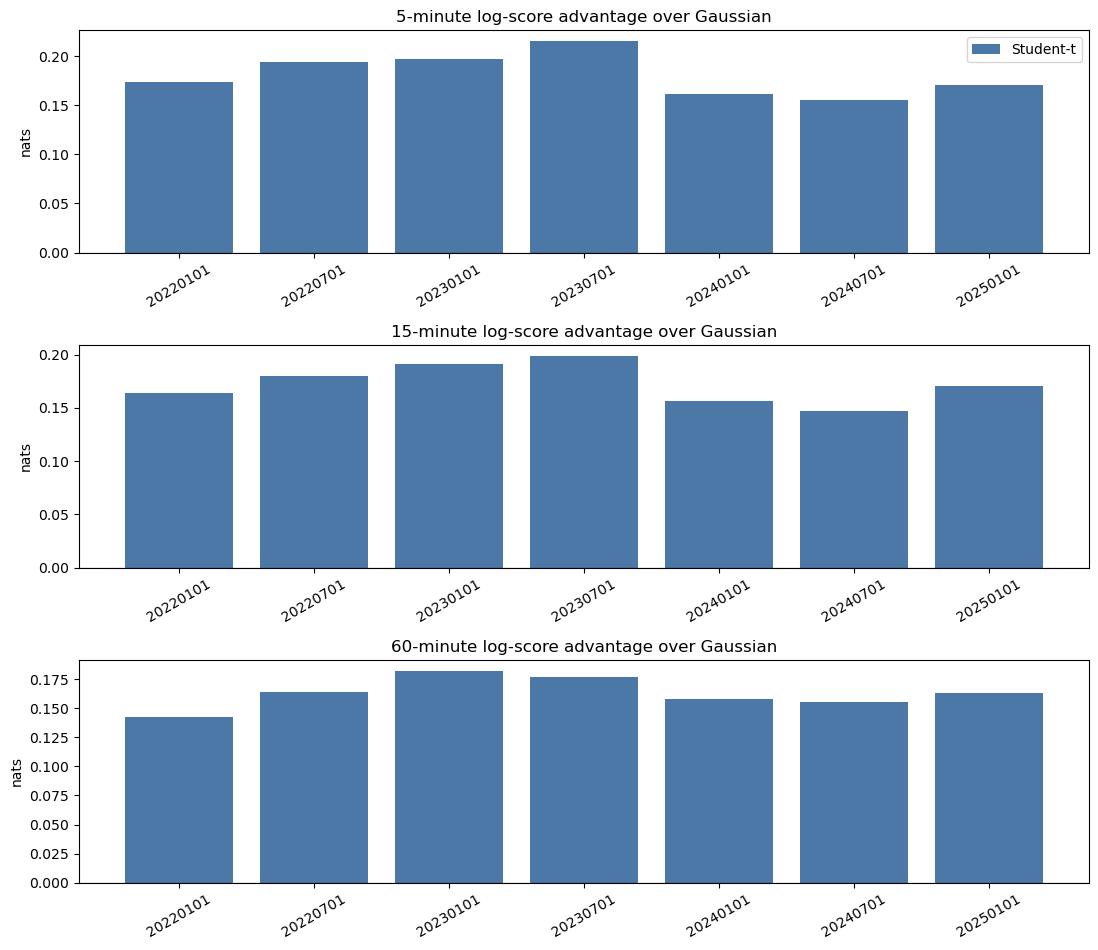

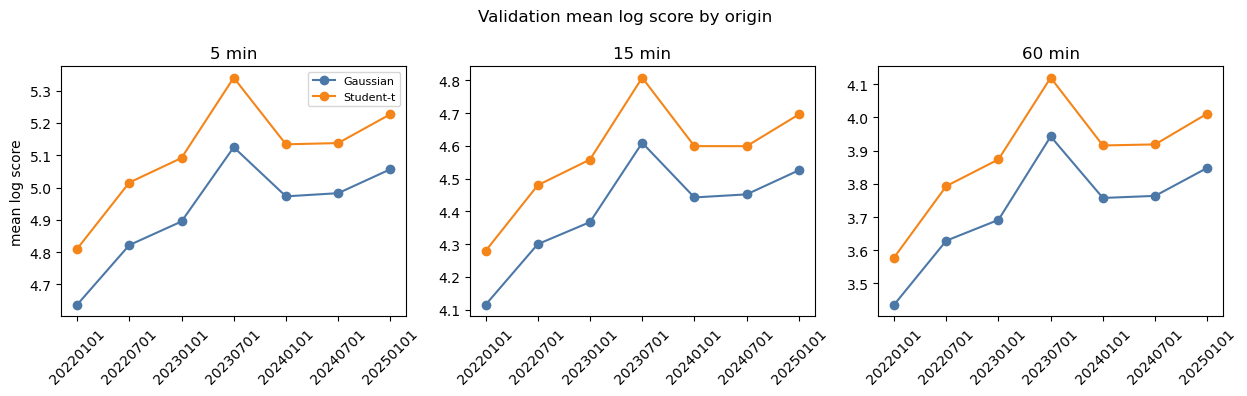

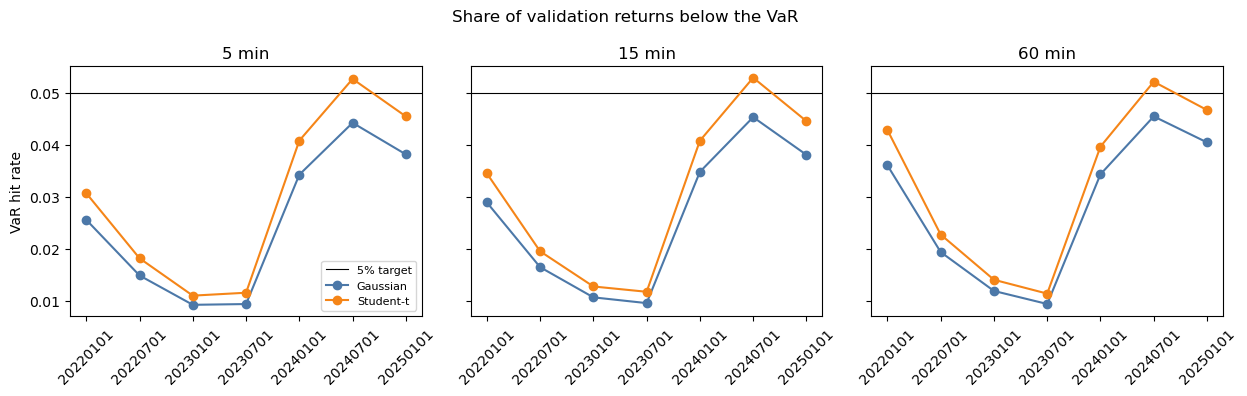

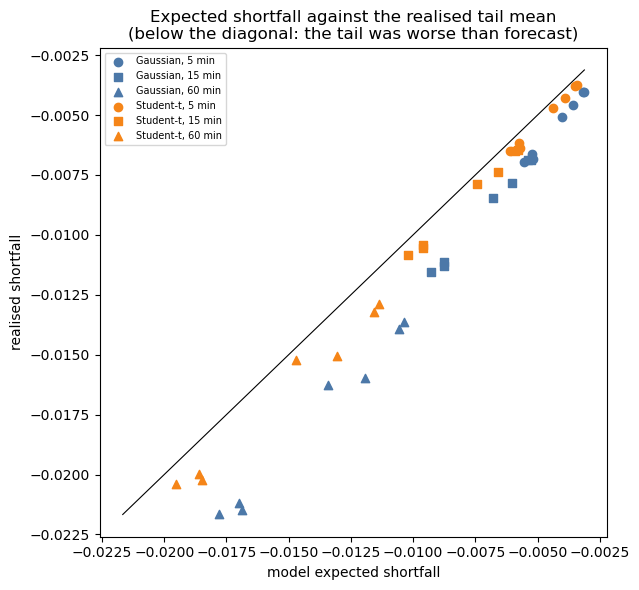

In [5]:
plot_advantage_by_origin(evaluation.scores, benchmark=BENCHMARK, candidates=CANDIDATES, labels=LABELS)
plt.show()
plot_score_levels(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()
plot_var_hit_rates(evaluation.scores, models=MODELS, alpha=ALPHA, labels=LABELS)
plt.show()
plot_shortfall(evaluation.scores, models=MODELS, labels=LABELS)
plt.show()

## Calibration diagnostics

The probability integral transform (PIT) of a well-calibrated density is uniform. Each panel plots PIT quantiles against uniform quantiles. The diagonal is perfect calibration. Faint lines are individual origins and heavy lines are their mean. An S-shaped curve means the tails carry the wrong amount of probability. A candidate improves calibration only if its heavy line sits closer to the diagonal than the benchmark's.

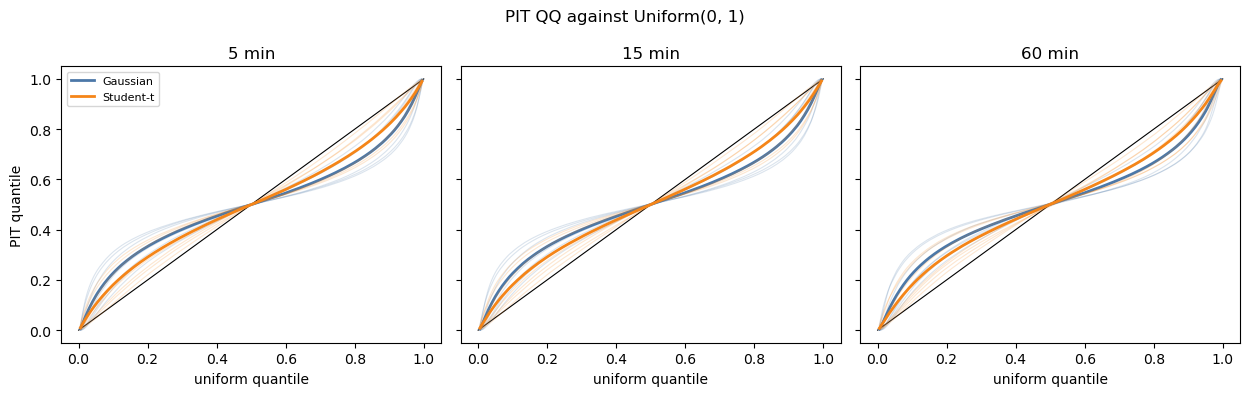

In [6]:
plot_pit_qq(evaluation.pit_qq, models=MODELS, labels=LABELS)
plt.show()

## Fitted densities

Each panel is the development-sample histogram of BTCUSDT log returns at one horizon, with a Gaussian and a Student-t fitted to that pooled sample. This shows the shape, not the rolling-origin models scored above. Returns whose outcome falls in the sealed year are excluded. The top row is the body. The bottom row uses a log scale and covers all but the outer 0.001% of each tail, which is where the two families differ most.

Pooled development fits


,observations,sealed_labels_held_out,gaussian_mean,gaussian_std,student_df,student_loc,student_scale
horizon_minutes,,,,,,,
5,3059995,525983,4.48301e-06,0.00206614,4.03485,4.48301e-06,0.00146728
15,3059985,525983,1.34468e-05,0.0034791,4.04498,1.34468e-05,0.00247373
60,3059940,525983,5.37982e-05,0.00677233,4.0831,5.37982e-05,0.00483724


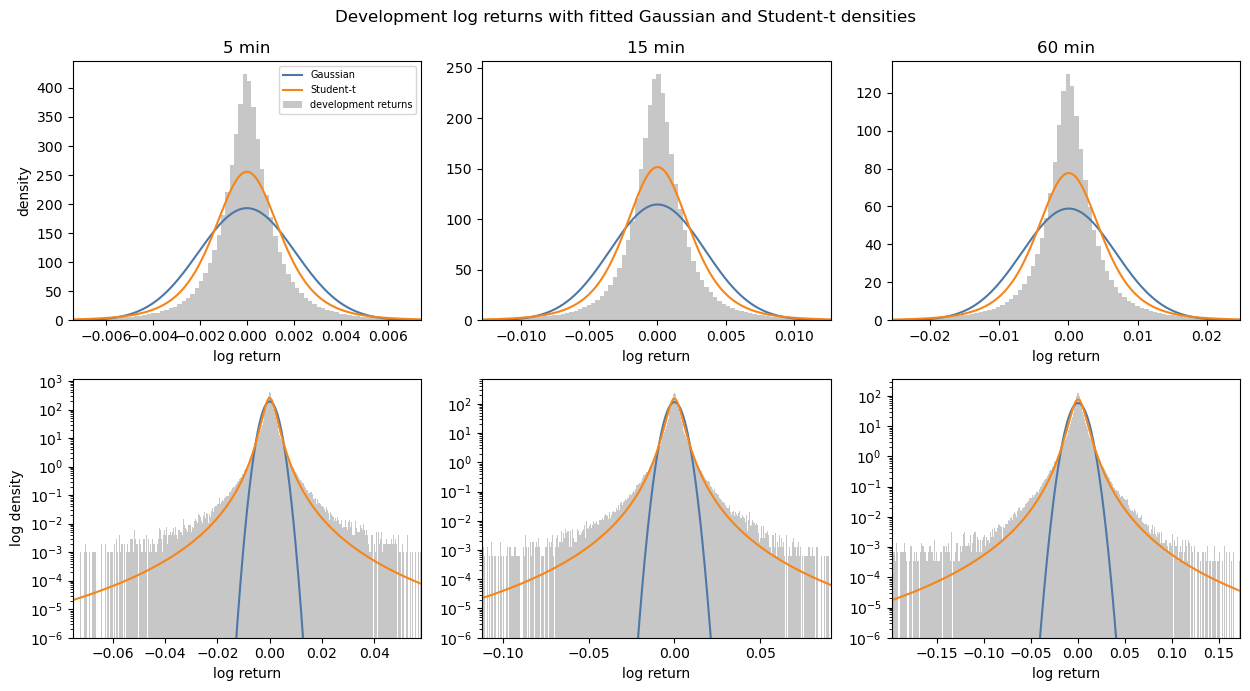

In [7]:
from research.distributions import fit_gaussian, fit_student_t
from research.returns import horizon_log_returns
from research.splits import development_returns

colors = model_colors(MODELS)
samples, curves, rows = {}, {}, []
for horizon in (int(value) for value in CONFIG["horizons_minutes"]):
    built = horizon_log_returns(kept["close"], horizon)
    sample, held_out = development_returns(built.returns, horizon, evaluation.boundary)
    if held_out == 0:
        raise RuntimeError(f"{horizon}-minute sample held out no sealed labels")
    values = sample.to_numpy(dtype=float)
    gaussian = fit_gaussian(values)
    student = fit_student_t(values)
    samples[horizon] = values
    curves[horizon] = [
        ("Gaussian", gaussian.log_density, {"color": colors["gaussian"]}),
        ("Student-t", student.log_density, {"color": colors["student_t"]}),
    ]
    rows.append(
        {
            "horizon_minutes": horizon,
            "observations": len(values),
            "sealed_labels_held_out": held_out,
            "gaussian_mean": gaussian.mean,
            "gaussian_std": gaussian.variance ** 0.5,
            "student_df": student.df,
            "student_loc": student.loc,
            "student_scale": student.scale,
        }
    )
fitted = pd.DataFrame(rows).set_index("horizon_minutes")
print("Pooled development fits")
display(fitted)
plot_density_panels(samples, curves, title="Development log returns with fitted Gaussian and Student-t densities")
plt.show()
NOTES = [
    f"Fitted shape: pooled Student-t degrees of freedom are {fitted['student_df'].min():.2f} to "
    f"{fitted['student_df'].max():.2f}. Values near 4 mean much heavier tails than a Gaussian; "
    f"the log-scale panels show the Gaussian assigning far too little probability to large moves."
]

## 18. Result

The next cell states the development result in plain English: the answer, why, how large the effect is at each horizon, whether the densities are calibrated, and what to do with the result.

In [8]:
result_lines = plain_english_result(
    question=QUESTION,
    verdict=verdict,
    reading=reading,
    calibration=calibration,
    failures=len(evaluation.failures),
    labels=LABELS,
)
for line in [*result_lines[:-1], *NOTES, result_lines[-1]]:
    print(line)
    print()

Question: Does a fat-tailed Student-t density forecast 5-, 15-, and 60-minute BTCUSDT returns better than a Gaussian?

Answer: yes, on development data. The null is rejected and the working forecast is Student-t.

Why: Student-t log score beats Gaussian at every horizon.

Against Gaussian, Student-t changed the geometric-mean forecast density by +19.8146% at 5 minutes (ahead at 7 of 7 origins); +18.8323% at 15 minutes (ahead at 7 of 7 origins); +17.7273% at 60 minutes (ahead at 7 of 7 origins).

Tail calibration: no model is calibrated. The 5% VaR is breached 2.56% to 3.97% of the time, and the Bonferroni test rejects coverage for every model and horizon. Every model breaches its VaR less often than it should, so each overstates tail risk. None of these densities is ready as a tail-risk estimate.

Every registered walk-forward window was scored.

What this means: use Student-t as the development working forecast. It is not retained until the sealed year confirms it.

Fitted shape: pool

## 19. Decision

The next cell records the development result on `EXP-H01`. Accepting or rejecting the development null sets status `Exploratory`, names the working forecast in `result`, and leaves the lifecycle decision blank. Incomplete evidence sets `Deferred`. Only `confirm_h1`, run on the sealed year, writes `retain` or `reject`. The cell then lists what still blocks that confirmation.

In [9]:
record = record_development_decision(
    RECORD_PATH,
    verdict,
    experiment_id=EXPERIMENT_ID,
    dataset_id=DATASET_ID,
    dataset_digest=DATASET_DIGEST,
    config=CONFIG,
    root=root,
)
print(f"Recorded on {record.experiment_id}: status={record.status}, result={record.result}, "
      f"lifecycle decision={record.decision or '(blank)'}")
display(pd.Series(asdict(record), name="registry value").to_frame())
blockers = confirmation_blockers(
    root=root,
    record=record,
    h1_record=GATE_H1_RECORD,
    dataset_objects=GATE_OBJECTS,
)
if blockers:
    print("Sealed confirmation is blocked:")
    for blocker in blockers:
        print(f"- {blocker}")
else:
    print("Sealed confirmation has no outstanding blockers. It can be run once, below.")

Research code version is dirty: 3a26af0dc855774a6debbdd60d0e88fb244f2577+dirty


Recorded on EXP-H01: status=Exploratory, result=student_t, lifecycle decision=(blank)


,registry value
experiment_id,EXP-H01
hypothesis,"A Student-t model of 5-, 15-, and 60-minute BT..."
null,The Student-t model has no incremental calibra...
parent_hypothesis,None
dataset_id,btcusdt-1m
dataset_digest,d67871b2eebd796cb37c7cafa89677fbca4b31ad0bdae9...
code_version,3a26af0dc855774a6debbdd60d0e88fb244f2577+dirty
config_digest,5c06edef219302cfc2906f7a4b2ef4a1e643a36cfe7bc0...
status,Exploratory
result,student_t


Research code version is dirty: 3a26af0dc855774a6debbdd60d0e88fb244f2577+dirty


Sealed confirmation is blocked:
- the research code is uncommitted (3a26af0dc855774a6debbdd60d0e88fb244f2577+dirty)


## Sealed confirmation

This cell reads the final 12 months once, writes `retain` or `reject` with a run id, and cannot be repeated. It is off by default. Set `RUN_SEALED_CONFIRMATION = True` only after the blockers printed above are cleared and the code is committed.

In [ ]:
RUN_SEALED_CONFIRMATION = False

if not RUN_SEALED_CONFIRMATION:
    print("Sealed confirmation was not run. No sealed labels were read.")
else:
    if blockers:
        raise RuntimeError("sealed confirmation is blocked: " + "; ".join(blockers))

    from research.evaluate import confirm_h1

    confirmation = confirm_h1(
        kept["close"],
        record,
        dataset_id=DATASET_ID,
        dataset_digest=DATASET_DIGEST,
        root=root,
        record_path=RECORD_PATH,
    )
    print(f"decision={confirmation.record.decision} result={confirmation.record.result} "
          f"status={confirmation.record.status} run_id={confirmation.record.run_id}")
    display(confirmation.scores)

RuntimeError: sealed confirmation is blocked: the research code is uncommitted (3a26af0dc855774a6debbdd60d0e88fb244f2577+dirty)

## 20. Reusable implementation extracted

`research.returns`, `research.distributions`, `research.splits`, and `research.evaluate` hold the calculations. `research.report` holds the shared reading, plots, and registration. This notebook only loads data, calls them, and renders the result.

## 21. Next experiment

H2 (`03_regime_models`) uses the working density named here as its unconditional benchmark. Rejection of Student-t leaves Gaussian.